# Generation checks

Diagnostics for the synthetic activation dataset produced by `src/generator/`.
This notebook describes the dataset: how the classes and typologies are
composed, how separable each feature is on its own, and how a plain logistic
regression scores.

**Nothing here is a gate.** The three checks at the end (highest single-feature
AUC, strongest label correlation, logistic regression PR-AUC) are printed next
to reference levels, but no dataset is accepted or rejected on them and no
generator parameter is tuned to move them. They were used as an acceptance
gate in Phase 2; that use was withdrawn at supervisor review because it made
the dataset's difficulty a function of the desired result.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

REPO_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))

from src.eval.report import build_report
from src.generator.features import T0_FEATURES, T7_FEATURES

pd.set_option("display.width", 160)
pd.set_option("display.max_rows", 80)
pd.set_option("display.max_columns", 20)

report = build_report(write=False)
summary = report["manifest"]["summary"]
matrix = report["matrix"]
labels = report["labels"]
feature_group = {name: "T0" for name in T0_FEATURES} | {name: "T7" for name in T7_FEATURES}

print(f"{summary['num_activations']} activations, {summary['num_agents']} agents")
print(f"agent type counts {summary['agent_type_counts']}")
print(f"realised fraud rate {summary['realised_fraud_rate']:.4f}")

89695 activations, 350 agents
agent type counts {'honest': 273, 'opportunistic': 59, 'systematic': 18}
realised fraud rate 0.0714


## Dataset summary

In [2]:
keys = [
    "num_activations", "num_agents", "agent_type_counts", "num_activity_rows",
    "num_customers_used", "num_devices", "first_submission", "last_submission",
    "realised_fraud_rate", "careful_fraud_count", "ambiguous_count", "ambiguous_share",
]
pd.Series({key: summary[key] for key in keys}).to_frame("value")

,value
num_activations,89695
num_agents,350
agent_type_counts,"{'honest': 273, 'opportunistic': 59, 'systemat..."
num_activity_rows,717560
num_customers_used,87030
num_devices,441
first_submission,2025-01-06 00:00:00
last_submission,2025-07-04 23:58:48
realised_fraud_rate,0.071442
careful_fraud_count,1109


## Records per typology

Fraud is committed by agents in episodes, not drawn per row. The agent honesty
mix is stratified, so the number of agents of each type is identical for every
seed; realised prevalence across seeds is in `outputs/prevalence_by_seed.csv`.

In [3]:
report["typologies"]

,records,share_of_all_records
fraud_typology,,
none,83287,0.928558
sim_farming,2597,0.028954
ghost,1738,0.019377
payout_gaming,1101,0.012275
collusion,972,0.010837


In [4]:
pd.Series(summary["mode_counts"]).sort_values(ascending=False).to_frame("records")

,records
legit_normal,63516
legit_dormant,15995
legit_trial_lapse,3776
fraud_sim_farming,2597
fraud_ghost,1738
fraud_payout_gaming,1101
fraud_collusion,972


## Prevalence floor

The target prevalence is derived from the evaluation design, not from any model
score: it is the lowest rate at which the rarest typology still averages about
100 positives per test fold (see the `prevalence` section of
`config/generator.yaml`). The arithmetic is recomputed here on the realised data.

In [5]:
pd.Series(report["prevalence_floor"]).to_frame("value")

,value
realised_fraud_rate,0.071442
test_period_activations,44167.0
rarest_typology,collusion
rarest_typology_share_of_fraud,0.151685
implied_prevalence_floor,0.074633
expected_rarest_positives_per_fold,95.725122


## Ambiguous cases

Hard cases are generated deliberately in both directions: legitimate records
carrying several fraud-like situations at once, and fraudulent records
committed carefully enough to imitate ordinary behaviour.

In [6]:
report["ambiguity"]

,case,records,share_of_all_records
0,legitimate records that look fraudulent,8538,0.095189
1,fraudulent records committed carefully,1109,0.012364
2,all ambiguous records,9647,0.107553


Each fraud-like situation below also occurs in legitimate records. That
overlap is what stops any single feature from separating the classes.

In [7]:
report["flags"]

,situation,legitimate_records,legitimate_share,fraudulent_records,fraudulent_share
0,dormant,15995,0.192047,0,0.000000
1,burst_day,47767,0.573523,3700,0.577403
2,shared_device,3570,0.042864,1310,0.204432
3,same_day_sim,14907,0.178984,1219,0.190231
4,fixed_site,7511,0.090182,0,0.000000
5,end_cycle_push,18956,0.227599,3020,0.471286
6,repeat_msisdn,1808,0.021708,857,0.133739


## Single-feature AUC

Each feature used alone, oriented so the value never falls below 0.5.

In [8]:
auc_table = pd.DataFrame({"single_feature_auc": report["auc"].round(3)})
auc_table["group"] = [feature_group[name] for name in auc_table.index]
auc_table

,single_feature_auc,group
customer_active_days_7d,0.794,T7
usage_minutes_total_7d,0.785,T7
agent_activation_velocity_24h,0.770,T0
transaction_count_7d,0.759,T7
days_to_first_customer_activity,0.729,T7
topup_amount_total_7d,0.727,T7
device_activations_7d,0.711,T0
agent_tenure_days,0.704,T0
agent_activation_velocity_1h,0.668,T0
distinct_devices_used_30d,0.654,T0


## Correlation with the label

In [9]:
correlation_table = report["correlation"].to_frame("correlation_with_label")
correlation_table["absolute"] = correlation_table["correlation_with_label"].abs()
correlation_table.round(3)

,correlation_with_label,absolute
agent_activation_velocity_24h,0.315,0.315
days_to_first_customer_activity,0.263,0.263
customer_active_days_7d,-0.260,0.260
device_activations_7d,0.247,0.247
agent_activation_velocity_1h,0.223,0.223
distinct_devices_used_30d,0.199,0.199
ip_location_mismatch_flag,0.185,0.185
job_acceptance_latency_seconds,0.180,0.180
proof_of_activation_missing_flag,0.169,0.169
agent_tenure_days,-0.161,0.161


## Correlation among the T7 features

Transactions, topup and usage minutes each have their own per-customer
propensity and their own day-to-day noise, sharing one common component. They
should be positively correlated with each other and with active days, but not
collinear.

In [10]:
short = {name: name.replace("customer_", "").replace("_7d", "").replace("_total", "") for name in T7_FEATURES}
print("Spearman")
display(report["t7_spearman"].rename(index=short, columns=short).round(2))
print("Pearson")
display(report["t7_pearson"].rename(index=short, columns=short).round(2))

Spearman


,active_days,days_to_first_activity,transaction_count,topup_amount,usage_minutes,support_contact_count,complaint_or_refund_flag,sim_active_at_day7,activity_dropoff_flag
active_days,1.00,-0.75,0.78,0.68,0.84,0.19,0.0,0.21,-0.19
days_to_first_activity,-0.75,1.00,-0.65,-0.58,-0.71,-0.14,-0.0,-0.20,-0.18
transaction_count,0.78,-0.65,1.00,0.61,0.75,0.15,0.0,0.19,-0.13
topup_amount,0.68,-0.58,0.61,1.00,0.65,0.13,-0.0,0.16,-0.10
usage_minutes,0.84,-0.71,0.75,0.65,1.00,0.16,-0.0,0.21,-0.12
support_contact_count,0.19,-0.14,0.15,0.13,0.16,1.00,-0.0,0.04,-0.04
complaint_or_refund_flag,0.00,-0.00,0.00,-0.00,-0.00,-0.00,1.0,-0.00,-0.00
sim_active_at_day7,0.21,-0.20,0.19,0.16,0.21,0.04,-0.0,1.00,-0.02
activity_dropoff_flag,-0.19,-0.18,-0.13,-0.10,-0.12,-0.04,-0.0,-0.02,1.00


Pearson


,active_days,days_to_first_activity,transaction_count,topup_amount,usage_minutes,support_contact_count,complaint_or_refund_flag,sim_active_at_day7,activity_dropoff_flag
active_days,1.00,-0.76,0.50,0.35,0.54,0.19,0.00,0.21,-0.22
days_to_first_activity,-0.76,1.00,-0.37,-0.26,-0.39,-0.14,-0.00,-0.21,-0.19
transaction_count,0.50,-0.37,1.00,0.29,0.41,0.09,-0.00,0.11,-0.12
topup_amount,0.35,-0.26,0.29,1.00,0.30,0.07,-0.00,0.07,-0.08
usage_minutes,0.54,-0.39,0.41,0.30,1.00,0.10,-0.01,0.12,-0.13
support_contact_count,0.19,-0.14,0.09,0.07,0.10,1.00,-0.00,0.04,-0.04
complaint_or_refund_flag,0.00,-0.00,-0.00,-0.00,-0.01,-0.00,1.00,-0.00,-0.00
sim_active_at_day7,0.21,-0.21,0.11,0.07,0.12,0.04,-0.00,1.00,-0.02
activity_dropoff_flag,-0.22,-0.19,-0.12,-0.08,-0.13,-0.04,-0.00,-0.02,1.00


## Logistic regression on the raw features

Plain logistic regression on all T0 and T7 features, scored with the same
repeated grouped, time-ordered cross-validation used for the models (see
`config/model.yaml`). No resampling: PR-AUC is threshold free. Prevalence is
reported per fold because PR-AUC depends on it.

In [11]:
folds = report["logreg_folds"]
display(folds.round(4))
print(f"PR-AUC  {folds['pr_auc'].mean():.3f} (sd {folds['pr_auc'].std(ddof=1):.3f})")
print(f"ROC-AUC {folds['roc_auc'].mean():.3f} (sd {folds['roc_auc'].std(ddof=1):.3f})")

,repeat,fold,prevalence,pr_auc,roc_auc
0,0,0,0.0721,0.6630,0.9104
1,0,1,0.0738,0.7181,0.9252
2,0,2,0.0857,0.7589,0.9416
3,0,3,0.0720,0.7130,0.9420
4,0,4,0.0796,0.6804,0.9244
5,1,0,0.0713,0.7250,0.9337
6,1,1,0.0750,0.7117,0.9303
7,1,2,0.0786,0.7027,0.9165
8,1,3,0.0813,0.7197,0.9359
9,1,4,0.0770,0.6945,0.9320


PR-AUC  0.708 (sd 0.030)
ROC-AUC 0.929 (sd 0.011)


## Overlap between the classes

One histogram per feature, legitimate against fraudulent, each normalised to a
density so the rare class stays visible.

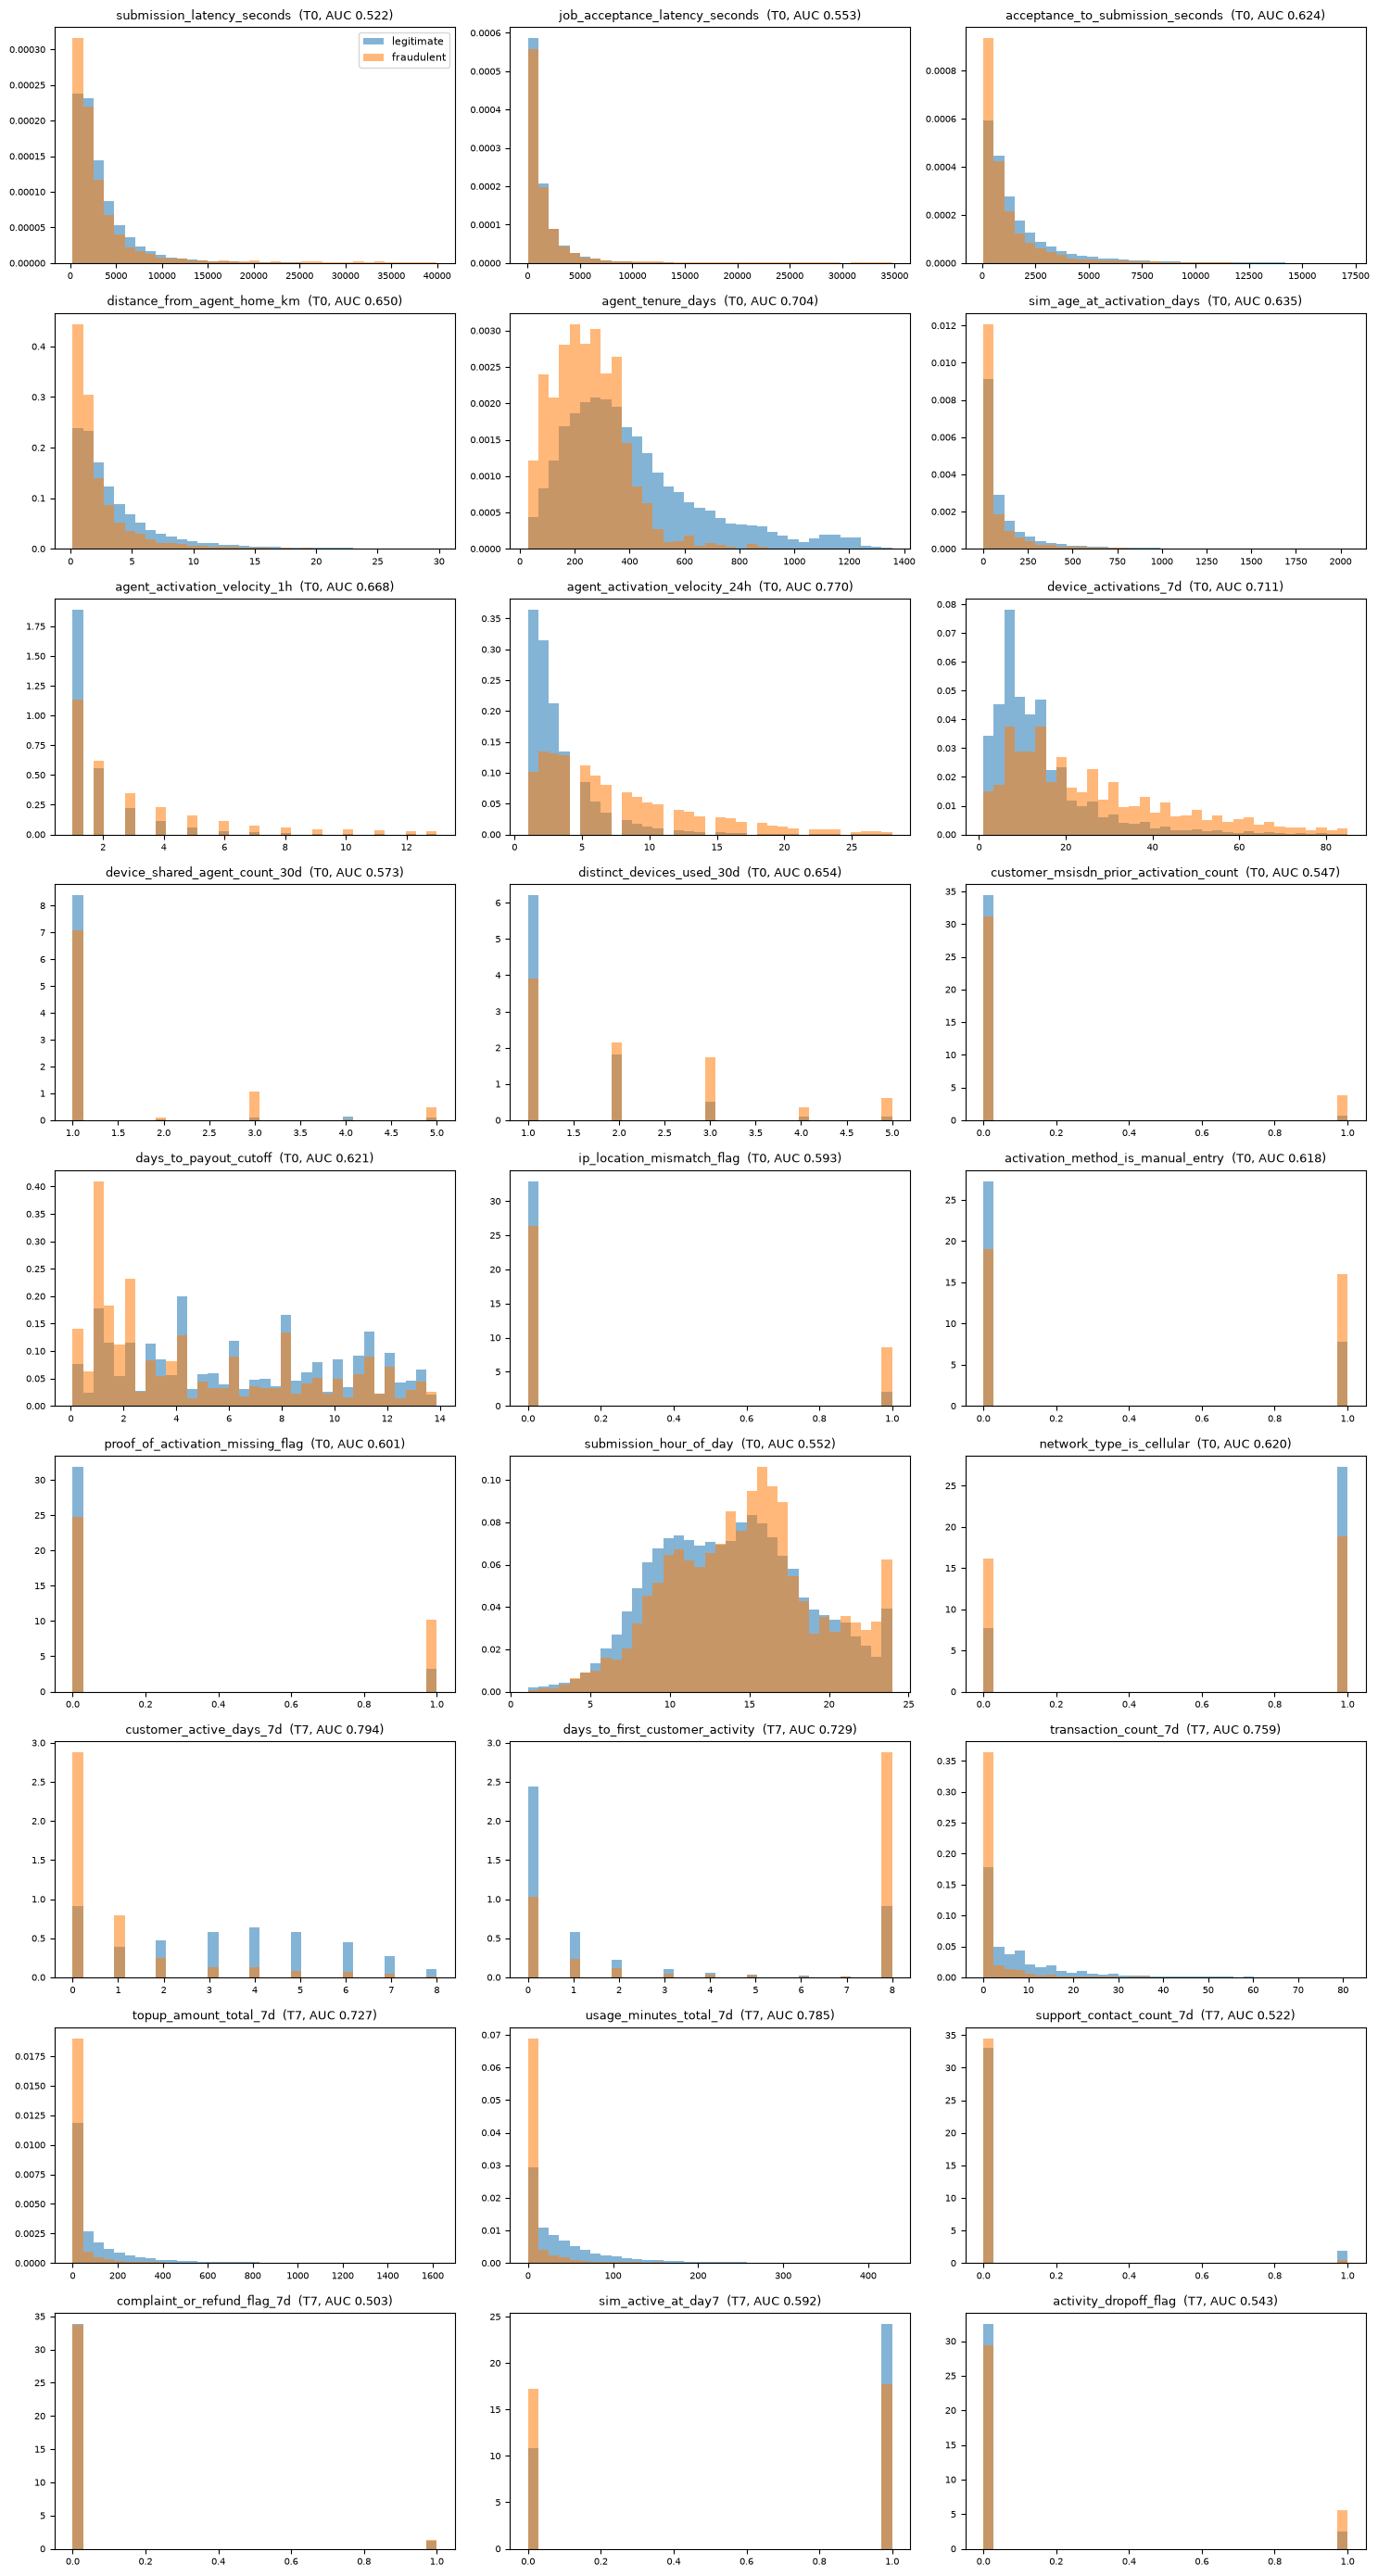

In [12]:
features = list(matrix.columns)
columns = 3
rows = int(np.ceil(len(features) / columns))
fig, axes = plt.subplots(rows, columns, figsize=(15, 3.1 * rows))

legitimate = matrix[labels == 0]
fraudulent = matrix[labels == 1]

for axis, name in zip(axes.ravel(), features):
    values = matrix[name].to_numpy(dtype=float)
    low, high = np.percentile(values, [0.5, 99.5])
    if high <= low:
        low, high = values.min(), values.min() + 1.0
    bins = np.linspace(low, high, 36)
    axis.hist(legitimate[name], bins=bins, density=True, alpha=0.55, label="legitimate")
    axis.hist(fraudulent[name], bins=bins, density=True, alpha=0.55, label="fraudulent")
    axis.set_title(f"{name}  ({feature_group[name]}, AUC {report['auc'][name]:.3f})", fontsize=9)
    axis.tick_params(labelsize=7)

for axis in axes.ravel()[len(features):]:
    axis.axis("off")

axes.ravel()[0].legend(fontsize=8)
fig.tight_layout()

figure_dir = REPO_ROOT / "outputs" / "figures"
figure_dir.mkdir(parents=True, exist_ok=True)
fig.savefig(figure_dir / "feature_overlap.png", dpi=110)
plt.show()

## Diagnostics

Reported against reference levels. `gates_anything` is False by construction.

In [13]:
report["diagnostics_table"]

,check,value,sd_across_folds,detail,reference,inside_reference,gates_anything
0,max single-feature AUC,0.794438,NaN,customer_active_days_7d,<= 0.85,True,False
1,max absolute label correlation,0.315093,NaN,agent_activation_velocity_24h,<= 0.9,True,False
2,"logistic regression PR-AUC (T0+T7 features, cr...",0.708433,0.030372,dataset prevalence 0.0714,"[0.65, 0.8]",True,False
